# Fixed-cohort 90-day lifecycle analysis (round 2)

Project: **From Hype to Sustainability: Lifecycle Patterns of AI-Related GitHub Repositories** (CS5488)

Round 2 answers a different question from the round-1 notebook. Round 1 measured what the data
contains; this notebook tracks **one fixed cohort of AI repositories** and follows each repository
through the three bands after its creation:

| Band | Age days | UTC day window (creation day = day 1) |
|---|---|---|
| `day_1_30` | 1-30 | created + 0 .. created + 29 |
| `day_31_60` | 31-60 | created + 30 .. created + 59 |
| `day_61_90` | 61-90 | created + 60 .. created + 89 |

Rules this notebook implements:

* The cohort is fixed **once** (valid metadata + `ai_label_final == included` + created-date range).
  It is never re-selected per band; a repository with no activity after day 60 stays in the list.
* A band with a fully covered window and no events is a real **0**. A band whose source days were
  not fully processed is marked **incomplete** and is not read as zero activity.
* Official figures keep one fixed denominator for all three bands: the repositories whose whole
  90-day window was fully covered. Repositories that fall short are reported next to them and are
  never folded into the ratio or the distributions.

**Everything in this notebook is Testing Data** - fictional repository ids, simulated AI labels and
hand-built activity, used only to verify the program. The inputs live in `testing_data/`, the tables
and figures it writes stay in `c_lifecycle_analysis/testing_results/`, and neither may be mixed into
real statistics. Input contract: see `C_分析修订与双年份准备.md`, section "Testing Data 输入接口标准".

## 0. Setup

In [1]:
from pathlib import Path
import copy
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the repository root whether the notebook is run from the repo root or from this folder,
# then import the shared, configurable analysis module.
PROJECT = Path.cwd()
while PROJECT != PROJECT.parent and not (PROJECT / "c_lifecycle_analysis").is_dir():
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / "c_lifecycle_analysis"))

from cohort_analysis import (  # noqa: E402
    BAND_ORDER,
    aggregate_cohort,
    analyze_cohort,
    per_repo_stage_table,
    read_coverage,
    read_daily_counts,
)

TESTING_ROOT = PROJECT / "testing_data"
RESULTS_DIR = PROJECT / "c_lifecycle_analysis" / "testing_results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DATA_KIND = "Testing Data"

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

print("repository root  :", PROJECT)
print("testing inputs   :", TESTING_ROOT)
print("results, figures :", RESULTS_DIR)
print()
print(f"This notebook reads {DATA_KIND} only. Every table and figure it writes stays under")
print("testing_results/, so nothing here can be mixed into real statistics.")

repository root  : E:\A_2026CityU\C5488\group work\github_activity_analyze_project
testing inputs   : E:\A_2026CityU\C5488\group work\github_activity_analyze_project\testing_data
results, figures : E:\A_2026CityU\C5488\group work\github_activity_analyze_project\c_lifecycle_analysis\testing_results

This notebook reads Testing Data only. Every table and figure it writes stays under
testing_results/, so nothing here can be mixed into real statistics.


## 1. Testing Data inputs

Four inputs per year, matching the documented contract:

| File | Content |
|---|---|
| `repo_metadata.csv` | one row per repo, `repo_created_at` with time-of-day, `fetch_status`, `api_repo_id` |
| `repo_ai_labels_analysis.csv` | one row per repo, `ai_label_final` |
| `repo_daily_counts.parquet` | `repo_id` + UTC `event_date` + `event_type` + `event_count` |
| `coverage.json` / `coverage_missing.json` | which hours were fully processed |

The complete coverage window spans 2024-04-01 .. 2024-07-28 (and 2026-04-01 .. 2026-07-28), which
contains every April-created cohort repository's day 1-90 window. `coverage_missing.json` drops all
hours of 07-01 .. 07-05, which falls inside the day-61-90 window of the later-created repositories.

In [2]:
inventory = []
for year in (2024, 2026):
    year_dir = TESTING_ROOT / str(year)
    full = read_coverage(year_dir / "coverage.json")
    missing = read_coverage(year_dir / "coverage_missing.json")
    inventory.append(
        dict(
            year=year,
            files=len(list(year_dir.iterdir())),
            requested_days=len(full["requested_days"]),
            requested_hours=full["requested_hours"],
            verified_hours_full=full["verified_hours"],
            verified_hours_missing=missing["verified_hours"],
            missing_hours=len(missing["missing_source_hours"]),
        )
    )
print(f"{DATA_KIND} input inventory")
print(pd.DataFrame(inventory).to_string(index=False))
print()
for year in (2024, 2026):
    cov = read_coverage(TESTING_ROOT / str(year) / "coverage.json")
    print(
        f"{year}: complete coverage spans {cov['requested_days_parsed'][0].date()} .. "
        f"{cov['requested_days_parsed'][-1].date()} "
        f"({len(cov['complete_days'])} fully verified UTC days)"
    )

Testing Data input inventory
 year  files  requested_days  requested_hours  verified_hours_full  verified_hours_missing  missing_hours
 2024      5             119             2856                 2856                    2736            120
 2026      5             119             2856                 2856                    2736            120

2024: complete coverage spans 2024-04-01 .. 2024-07-28 (119 fully verified UTC days)
2026: complete coverage spans 2026-04-01 .. 2026-07-28 (119 fully verified UTC days)


## 2. 2024 cohort, complete coverage

`run_year()` is the only place that knows about a year: it switches the four input paths, the
created-date range and the cohort year. The computation behind it is identical for every year.

In [3]:
def run_year(year, coverage_name="coverage.json"):
    year_dir = TESTING_ROOT / str(year)
    return analyze_cohort(
        metadata_path=year_dir / "repo_metadata.csv",
        labels_path=year_dir / "repo_ai_labels_analysis.csv",
        daily_counts_path=year_dir / "repo_daily_counts.parquet",
        coverage_path=year_dir / coverage_name,
        cohort_year=year,
        created_from=f"{year}-04-01",
        created_to=f"{year}-04-30",
        data_kind=DATA_KIND,
    )


res24 = run_year(2024)

print(f"{DATA_KIND} 2024 - fixed AI cohort: {len(res24['cohort'])} repositories")
print("cohort repositories (creation day = day 1):")
print(res24["cohort"].to_string(index=False))
print()
excl = {k: v for k, v in res24["exclusions"].items() if not k.endswith("_repo_ids")}
print("repositories excluded before the cohort was fixed:")
print(pd.Series(excl, dtype="object").to_string())
print()
print("per-repository x band intermediate table (3 rows per repository, zero rows kept):")
print(res24["stage_table"].to_string(index=False))

Testing Data 2024 - fixed AI cohort: 4 repositories
cohort repositories (creation day = day 1):
           repo_id           repo_created_at repo_created_day
900000000000000001 2024-04-01 12:00:00+00:00       2024-04-01
900000000000000002 2024-04-02 09:30:00+00:00       2024-04-02
900000000000000003 2024-04-03 23:45:00+00:00       2024-04-03
900000000000000004 2024-04-04 00:05:00+00:00       2024-04-04

repositories excluded before the cohort was fixed:
fetch_status_not_ok          1
api_repo_id_mismatch         1
creation_time_unparseable    1
invalid_metadata_rows        3
no_label                     1
uncertain                    1
excluded                     1
out_of_range                 1
cohort_size                  4

per-repository x band intermediate table (3 rows per repository, zero rows kept):
 cohort_year    data_kind            repo_id           repo_created_at      band  band_day_start  band_day_end  required_days  covered_days  band_complete coverage_status  counts_a

In [4]:
print("cohort summary by band (Testing Data 2024, complete coverage):")
print(res24["aggregate"].to_string(index=False))
print()
print("events outside the three bands (reported separately, never folded into a band):")
print(res24["out_of_band"].to_string(index=False))

cohort summary by band (Testing Data 2024, complete coverage):
 cohort_year    data_kind      band  cohort_size  complete_90d_repos  not_complete_90d_repos  active_repos  active_ratio  total_events_sum  events_median  events_q25  events_q75  active_days_median  active_days_q25  active_days_q75
        2024 Testing Data  day_1_30            4                   4                       0             3          0.75                19            3.5        1.50        6.75                 2.5             1.50             3.25
        2024 Testing Data day_31_60            4                   4                       0             3          0.75                 9            2.0        0.75        3.50                 2.0             0.75             3.00
        2024 Testing Data day_61_90            4                   4                       0             2          0.50                13            1.5        0.00        4.75                 1.5             0.00             3.00

events o

## 3. Expected results for 2024

The expected values are derived by hand in `testing_data/README.md` from the constructed inputs.
Here they are compared against what the program **computed** from those inputs; the expected numbers
are never used as results.

In [5]:
METRICS = ["total_events", "active_days", "push_events", "issue_events",
           "issue_comment_events", "pr_events"]

expected_2024_exclusions = dict(
    invalid_metadata_rows=3, no_label=1, uncertain=1, excluded=1, out_of_range=1, cohort_size=4
)
for key, value in expected_2024_exclusions.items():
    assert res24["exclusions"][key] == value, (key, res24["exclusions"][key], value)
print("2024 exclusions match:", expected_2024_exclusions)

# (total_events, active_days, push_events, issue_events, issue_comment_events, pr_events)
expected_2024_stage = {
    (900000000000000001, "day_1_30"): (12, 4, 9, 3, 0, 0),
    (900000000000000001, "day_31_60"): (1, 1, 1, 0, 0, 0),
    (900000000000000001, "day_61_90"): (0, 0, 0, 0, 0, 0),
    (900000000000000002, "day_1_30"): (5, 3, 3, 0, 0, 2),
    (900000000000000002, "day_31_60"): (3, 3, 1, 1, 0, 1),
    (900000000000000002, "day_61_90"): (3, 3, 3, 0, 0, 0),
    (900000000000000003, "day_1_30"): (2, 2, 1, 0, 1, 0),
    (900000000000000003, "day_31_60"): (5, 3, 3, 1, 1, 0),
    (900000000000000003, "day_61_90"): (10, 3, 9, 0, 0, 1),
    (900000000000000004, "day_1_30"): (0, 0, 0, 0, 0, 0),
    (900000000000000004, "day_31_60"): (0, 0, 0, 0, 0, 0),
    (900000000000000004, "day_61_90"): (0, 0, 0, 0, 0, 0),
}
stage24 = res24["stage_table"].set_index(["repo_id", "band"])
for key, expected in expected_2024_stage.items():
    got = tuple(int(stage24.loc[key, m]) for m in METRICS)
    assert got == expected, (key, got, expected)
print(f"2024: all {len(expected_2024_stage)} repository x band rows match the expected values")

expected_2024_bands = {  # band -> complete 90d, not complete 90d, active, ratio, total, median events, median active days
    "day_1_30": (4, 0, 3, 0.75, 19, 3.5, 2.5),
    "day_31_60": (4, 0, 3, 0.75, 9, 2.0, 2.0),
    "day_61_90": (4, 0, 2, 0.50, 13, 1.5, 1.5),
}
agg24 = res24["aggregate"].set_index("band")
for band, (n_complete, n_incomplete, active, ratio, total, med_ev, med_ad) in expected_2024_bands.items():
    row = agg24.loc[band]
    assert (int(row.complete_90d_repos), int(row.not_complete_90d_repos), int(row.active_repos)) == (
        n_complete, n_incomplete, active), band
    assert abs(row.active_ratio - ratio) < 1e-9 and int(row.total_events_sum) == total, band
    assert abs(row.events_median - med_ev) < 1e-9, band
    assert abs(row.active_days_median - med_ad) < 1e-9, band
print("2024: cohort summary per band matches the expected figures")

out_of_band24 = res24["out_of_band"].set_index("repo_id")
assert int(out_of_band24.loc[900000000000000001, "pre_creation_events"]) == 1
assert int(out_of_band24.loc[900000000000000001, "beyond_90_events"]) == 1
assert int(out_of_band24.loc[900000000000000003, "beyond_90_events"]) == 2
print("2024: pre-creation and post-day-90 events are reported outside the three bands")

2024 exclusions match: {'invalid_metadata_rows': 3, 'no_label': 1, 'uncertain': 1, 'excluded': 1, 'out_of_range': 1, 'cohort_size': 4}
2024: all 12 repository x band rows match the expected values
2024: cohort summary per band matches the expected figures
2024: pre-creation and post-day-90 events are reported outside the three bands


## 4. 2024, deliberately incomplete coverage

`coverage_missing.json` drops 07-01 .. 07-05. The activity table still holds the 07-01 events, so
they are reported as **observed only**: the band is flagged incomplete and must not be read as a
zero-activity band.

The missing days are not earlier than day 61 in this cohort: they sit inside the day-61-90
window of the repositories created on 04-03 and 04-04. Because the official comparison needs one
fixed set of repositories, the two that do lose their 90-day coverage drop out of **every** band.

In [6]:
res24_missing = run_year(2024, "coverage_missing.json")

band3 = res24_missing["stage_table"].query("band == 'day_61_90'")
print("day 61-90 with coverage_missing.json:")
print(band3[["repo_id", "required_days", "covered_days", "coverage_status",
             "counts_are_observed_only", "total_events", "active_days"]].to_string(index=False))
print()
print(res24_missing["aggregate"].to_string(index=False))

stage_m24 = res24_missing["stage_table"].set_index(["repo_id", "band"])
agg_m24 = res24_missing["aggregate"].set_index("band")

assert stage_m24.loc[(900000000000000001, "day_61_90"), "coverage_status"] == "complete"
assert stage_m24.loc[(900000000000000002, "day_61_90"), "coverage_status"] == "complete"
assert int(stage_m24.loc[(900000000000000003, "day_61_90"), "covered_days"]) == 29
assert stage_m24.loc[(900000000000000003, "day_61_90"), "coverage_status"] == "incomplete"
assert int(stage_m24.loc[(900000000000000004, "day_61_90"), "covered_days"]) == 28
assert bool(stage_m24.loc[(900000000000000004, "day_61_90"), "counts_are_observed_only"]) is True
assert int(agg_m24.loc["day_61_90", "complete_90d_repos"]) == 2
assert int(agg_m24.loc["day_61_90", "not_complete_90d_repos"]) == 2
assert abs(agg_m24.loc["day_61_90", "active_ratio"] - 0.5) < 1e-9
assert int(agg_m24.loc["day_1_30", "complete_90d_repos"]) == 2   # one fixed 90-day set for every band
assert int(agg_m24.loc["day_31_60", "complete_90d_repos"]) == 2
assert abs(agg_m24.loc["day_1_30", "active_ratio"] - 1.0) < 1e-9  # that set is fully active here
assert abs(agg_m24.loc["day_31_60", "active_ratio"] - 1.0) < 1e-9
print()
print("2024: the incomplete band is flagged and its repositories stay in the table, but the")
print("official denominator becomes the 2 repositories covered for the whole 90 days, so every")
print("band is recomputed on that same fixed set.")

day 61-90 with coverage_missing.json:


           repo_id  required_days  covered_days coverage_status  counts_are_observed_only  total_events  active_days
900000000000000001             30            30        complete                     False             0            0
900000000000000002             30            30        complete                     False             3            3
900000000000000003             30            29      incomplete                      True            10            3
900000000000000004             30            28      incomplete                      True             0            0

 cohort_year    data_kind      band  cohort_size  complete_90d_repos  not_complete_90d_repos  active_repos  active_ratio  total_events_sum  events_median  events_q25  events_q75  active_days_median  active_days_q25  active_days_q75
        2024 Testing Data  day_1_30            4                   2                       2             2           1.0                17            8.5        6.75       10.25    

## 5. 2026 cohort - the year switch

Same function, four different input paths and a different created-date range. Different repository
ids and different counts confirm the switch really reads other inputs.

In [7]:
res26 = run_year(2026)
res26_missing = run_year(2026, "coverage_missing.json")

print(f"{DATA_KIND} 2026 - fixed AI cohort: {len(res26['cohort'])} repositories")
print(res26["cohort"].to_string(index=False))
print()
print("cohort summary by band (Testing Data 2026, complete coverage):")
print(res26["aggregate"].to_string(index=False))

ids24 = set(res24["cohort"]["repo_id"])
ids26 = set(res26["cohort"]["repo_id"])
assert len(res26["cohort"]) == 4
assert ids24 != ids26 and not (ids24 & ids26), "2024 and 2026 must read different cohorts"
assert res26["exclusions"]["invalid_metadata_rows"] == 3
assert res26["exclusions"]["cohort_size"] == 4

# (total_events, active_days, push_events, issue_events, issue_comment_events, pr_events)
expected_2026_stage = {
    (910000000000000001, "day_1_30"): (4, 2, 3, 1, 0, 0),
    (910000000000000001, "day_31_60"): (1, 1, 1, 0, 0, 0),
    (910000000000000001, "day_61_90"): (0, 0, 0, 0, 0, 0),
    (910000000000000002, "day_1_30"): (4, 1, 4, 0, 0, 0),
    (910000000000000002, "day_31_60"): (2, 1, 2, 0, 0, 0),
    (910000000000000002, "day_61_90"): (2, 1, 2, 0, 0, 0),
    (910000000000000003, "day_1_30"): (1, 1, 0, 0, 1, 0),
    (910000000000000003, "day_31_60"): (3, 1, 0, 0, 0, 3),
    (910000000000000003, "day_61_90"): (7, 1, 7, 0, 0, 0),
    (910000000000000004, "day_1_30"): (0, 0, 0, 0, 0, 0),
    (910000000000000004, "day_31_60"): (0, 0, 0, 0, 0, 0),
    (910000000000000004, "day_61_90"): (0, 0, 0, 0, 0, 0),
}
stage26 = res26["stage_table"].set_index(["repo_id", "band"])
for key, expected in expected_2026_stage.items():
    got = tuple(int(stage26.loc[key, m]) for m in METRICS)
    assert got == expected, (key, got, expected)
print(f"2026: all {len(expected_2026_stage)} repository x band rows match the expected values")

expected_2026_bands = {
    "day_1_30": (4, 0, 3, 0.75, 9, 2.5, 1.0),
    "day_31_60": (4, 0, 3, 0.75, 6, 1.5, 1.0),
    "day_61_90": (4, 0, 2, 0.50, 9, 1.0, 0.5),
}
agg26 = res26["aggregate"].set_index("band")
for band, (n_complete, n_incomplete, active, ratio, total, med_ev, med_ad) in expected_2026_bands.items():
    row = agg26.loc[band]
    assert (int(row.complete_90d_repos), int(row.not_complete_90d_repos), int(row.active_repos)) == (
        n_complete, n_incomplete, active), band
    assert abs(row.active_ratio - ratio) < 1e-9 and int(row.total_events_sum) == total, band
    assert abs(row.events_median - med_ev) < 1e-9, band
    assert abs(row.active_days_median - med_ad) < 1e-9, band
print()
print("2026: cohort summary per band matches the expected figures")

agg_m26 = res26_missing["aggregate"].set_index("band")
assert int(agg_m26.loc["day_61_90", "complete_90d_repos"]) == 2
assert int(agg_m26.loc["day_61_90", "not_complete_90d_repos"]) == 2
assert int(agg_m26.loc["day_1_30", "complete_90d_repos"]) == 2
print("2026: the missing-coverage variant behaves exactly like 2024 - one fixed set of 2 fully")
print("covered repositories provides the denominator for all three bands")

Testing Data 2026 - fixed AI cohort: 4 repositories

           repo_id           repo_created_at repo_created_day
910000000000000001 2026-04-01 08:00:00+00:00       2026-04-01
910000000000000002 2026-04-02 18:30:00+00:00       2026-04-02
910000000000000003 2026-04-03 06:15:00+00:00       2026-04-03
910000000000000004 2026-04-04 22:40:00+00:00       2026-04-04

cohort summary by band (Testing Data 2026, complete coverage):
 cohort_year    data_kind      band  cohort_size  complete_90d_repos  not_complete_90d_repos  active_repos  active_ratio  total_events_sum  events_median  events_q25  events_q75  active_days_median  active_days_q25  active_days_q75
        2026 Testing Data  day_1_30            4                   4                       0             3          0.75                 9            2.5        0.75        4.00                 1.0             0.75             1.25
        2026 Testing Data day_31_60            4                   4                       0             3          0.75                 6            1.5        0


2026: cohort summary per band matches the expected figures
2026: the missing-coverage variant behaves exactly like 2024 - one fixed set of 2 fully
covered repositories provides the denominator for all three bands


## 6. No repository covered for the whole 90 days

If no repository has a fully covered 90-day window, the fixed official denominator is empty, so the
active ratio, the event totals and the quantiles are **not computable** (NaN), never 0%. Here the
June days are removed, which breaks the day-61-90 window of every repository, so the whole official
comparison goes NaN.

In [8]:
coverage_no_band3 = copy.deepcopy(res24["coverage"])
coverage_no_band3["complete_days"] = [
    day for day in coverage_no_band3["complete_days"]
    if not (pd.Timestamp("2024-06-01") <= day <= pd.Timestamp("2024-06-30"))
]

stage_no_band3 = per_repo_stage_table(
    res24["cohort"],
    read_daily_counts(TESTING_ROOT / "2024" / "repo_daily_counts.parquet"),
    coverage_no_band3,
    cohort_year=2024,
    data_kind=DATA_KIND,
)
agg_no_band3 = aggregate_cohort(stage_no_band3, cohort_size=len(res24["cohort"]))
print(agg_no_band3.to_string(index=False))

assert (agg_no_band3["complete_90d_repos"] == 0).all()
assert (agg_no_band3["not_complete_90d_repos"] == 4).all()
assert agg_no_band3["active_ratio"].isna().all()
assert agg_no_band3["total_events_sum"].isna().all()
print()
print("no repository covered for the whole 90 days -> the ratio, the totals and the quantiles are")
print("not computable (NaN) in any band, never 0%.")

 cohort_year    data_kind      band  cohort_size  complete_90d_repos  not_complete_90d_repos  active_repos  active_ratio  total_events_sum  events_median  events_q25  events_q75  active_days_median  active_days_q25  active_days_q75
        2024 Testing Data  day_1_30            4                   0                       4             0           NaN               NaN            NaN         NaN         NaN                 NaN              NaN              NaN
        2024 Testing Data day_31_60            4                   0                       4             0           NaN               NaN            NaN         NaN         NaN                 NaN              NaN              NaN
        2024 Testing Data day_61_90            4                   0                       4             0           NaN               NaN            NaN         NaN         NaN                 NaN              NaN              NaN

no repository covered for the whole 90 days -> the ratio, the totals an

## 7. Export the intermediate tables

Per-repository x band tables and the cohort summaries are written next to the figures, in a
Testing-Data-only folder.

In [9]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
for year, res in ((2024, res24), (2026, res26)):
    res["cohort"].to_csv(RESULTS_DIR / f"cohort_list_testing_{year}.csv", index=False)
    res["stage_table"].to_csv(RESULTS_DIR / f"repo_stage_table_testing_{year}.csv", index=False)
    res["aggregate"].to_csv(RESULTS_DIR / f"cohort_summary_testing_{year}.csv", index=False)
    res["out_of_band"].to_csv(RESULTS_DIR / f"out_of_band_events_testing_{year}.csv", index=False)

print("written to", RESULTS_DIR)
for path in sorted(RESULTS_DIR.glob("*.csv")):
    print(" ", path.name)

written to E:\A_2026CityU\C5488\group work\github_activity_analyze_project\c_lifecycle_analysis\testing_results
  cohort_list_testing_2024.csv
  cohort_list_testing_2026.csv
  cohort_summary_testing_2024.csv
  cohort_summary_testing_2026.csv
  out_of_band_events_testing_2024.csv
  out_of_band_events_testing_2026.csv
  repo_stage_table_testing_2024.csv
  repo_stage_table_testing_2026.csv


## 8. Cohort figures

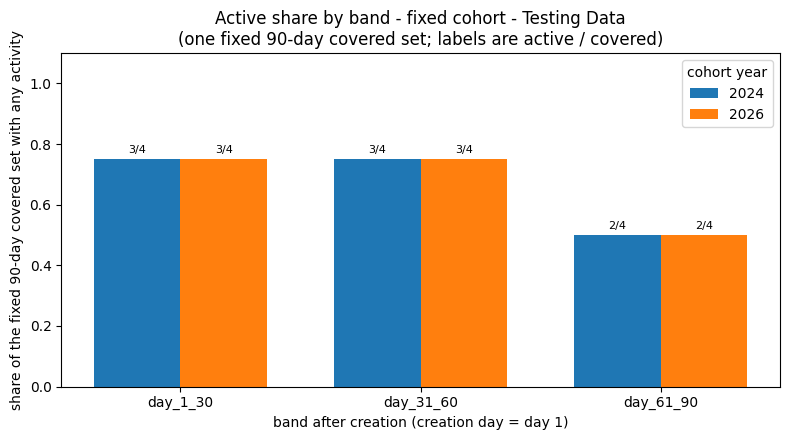

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(BAND_ORDER))
width = 0.36

for offset, (year, res) in zip((-0.5, 0.5), ((2024, res24), (2026, res26))):
    agg = res["aggregate"].set_index("band").reindex(BAND_ORDER)
    xpos = positions + offset * width
    ax.bar(xpos, agg["active_ratio"], width, label=str(year))
    for xi, ratio, active, complete in zip(
        xpos, agg["active_ratio"], agg["active_repos"], agg["complete_90d_repos"]
    ):
        ax.text(xi, ratio + 0.02, f"{int(active)}/{int(complete)}", ha="center", fontsize=8)

ax.set_xticks(positions)
ax.set_xticklabels(BAND_ORDER)
ax.set_xlabel("band after creation (creation day = day 1)")
ax.set_ylabel("share of the fixed 90-day covered set with any activity")
ax.set_ylim(0, 1.1)
ax.set_title(f"Active share by band - fixed cohort - {DATA_KIND}\n"
             "(one fixed 90-day covered set; labels are active / covered)")
ax.legend(title="cohort year")
fig.tight_layout()
fig.savefig(FIG_DIR / "cohort_active_ratio_by_band_testing.png", dpi=150)
plt.show()

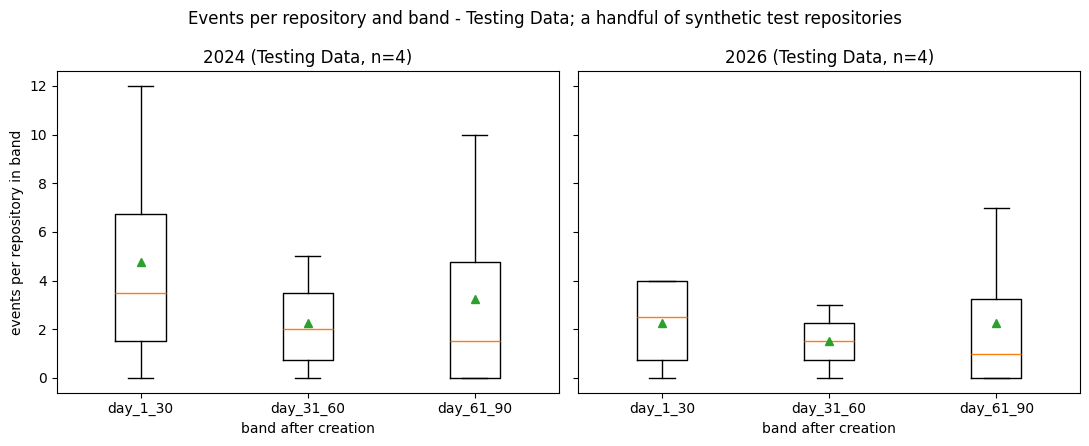

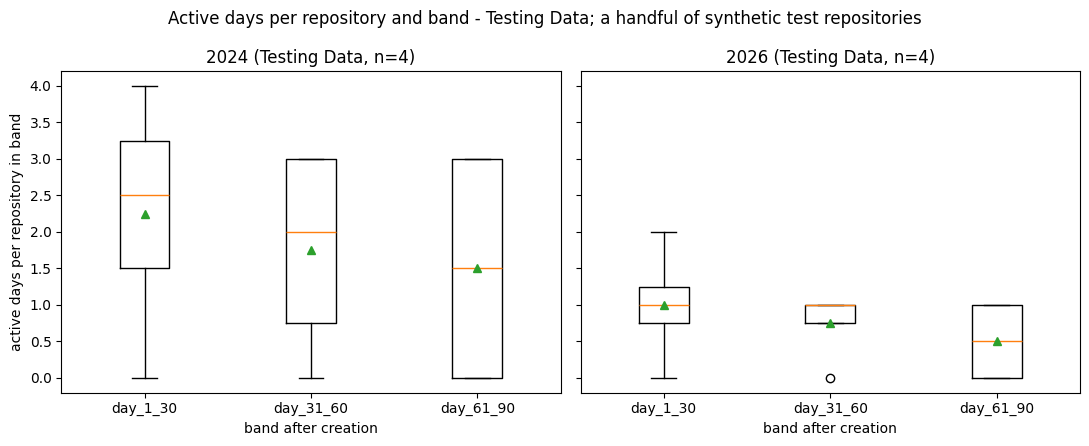

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (year, res) in zip(axes, ((2024, res24), (2026, res26))):
    st = res["stage_table"]
    completed = st[st.groupby("repo_id")["band_complete"].transform("all")]
    data = [completed.loc[completed["band"] == band, "total_events"].to_numpy() for band in BAND_ORDER]
    ax.boxplot(data, showmeans=True)
    ax.set_xticks(range(1, len(BAND_ORDER) + 1))
    ax.set_xticklabels(BAND_ORDER)
    ax.set_xlabel("band after creation")
    ax.set_title(f"{year} (Testing Data, n=4)")
axes[0].set_ylabel("events per repository in band")
fig.suptitle(f"Events per repository and band - {DATA_KIND}; a handful of synthetic test repositories")
fig.tight_layout()
fig.savefig(FIG_DIR / "cohort_events_by_band_testing.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (year, res) in zip(axes, ((2024, res24), (2026, res26))):
    st = res["stage_table"]
    completed = st[st.groupby("repo_id")["band_complete"].transform("all")]
    data = [completed.loc[completed["band"] == band, "active_days"].to_numpy() for band in BAND_ORDER]
    ax.boxplot(data, showmeans=True)
    ax.set_xticks(range(1, len(BAND_ORDER) + 1))
    ax.set_xticklabels(BAND_ORDER)
    ax.set_xlabel("band after creation")
    ax.set_title(f"{year} (Testing Data, n=4)")
axes[0].set_ylabel("active days per repository in band")
fig.suptitle(f"Active days per repository and band - {DATA_KIND}; a handful of synthetic test repositories")
fig.tight_layout()
fig.savefig(FIG_DIR / "cohort_active_days_by_band_testing.png", dpi=150)
plt.show()

## 9. Where round 2 stands

Delivered here:

* a configurable entry point (`c_lifecycle_analysis/cohort_analysis.py`) that takes the fixed cohort,
  the created-date range, the activity table and the coverage list, and switches all of it per year;
* the per-repository x band intermediate table (three rows per repository, zero-activity rows kept)
  with an explicit `coverage_status`;
* cohort summaries per band over one fixed 90-day denominator: the ratio, the event totals and
  the distributions use only repositories covered for the whole 90 days, and the uncovered count is
  reported next to them;
* Testing Data for 2024 and 2026, plus a deliberately incomplete coverage variant, with the expected
  results asserted above;
* figures for the active ratio, events and active days per band.

Still pending, and not blocking this round:

* the real cohort: `ai_label_final == included` from B, with the formal 2024 and 2026 created-date
  ranges confirmed by A;
* per-repository coverage lists for the real 90-day windows from A/D;
* the same analysis on Spark once the rolling monthly tables are ready;
* any claim that the band-to-band change is caused by agent adoption - the design compares two fixed
  cohorts and cannot support that on its own.